# M4 - Exploratory data analysis

**Steam Catalog Trends by Release Year** - exploration of the cleaned layer in `data/steam_catalog.db`.

The notebook **reads** the database through a read-only connection and never changes it (it hashes every table at
the start and checks the hashes again at the end). Every figure is written by code to `figures/`. Reused queries
live in `sql/queries/` and are loaded by name; parameters are bound, never formatted into SQL. Findings, labels and
limits are in [`docs/eda_report.md`](../docs/eda_report.md).

Run it on a fresh build:

```bash
python src/load.py
python src/clean.py
python src/validate.py
jupyter nbconvert --to notebook --execute --inplace notebooks/m4_eda.ipynb
```

Sections follow M4 section 2: 2.1 raw vs cleaned · 2.2 question and summary · 2.3 shape · 2.4 coverage and flag
filter · 2.5 time · 2.6 relationships · 2.7 one comparison · decisions.

In [1]:
# ---------------- parameters: every choice this notebook makes ----------------
# Flag filters (review_snapshot_clean). Reported: Steam shows a score (>= 10 reviews), very popular games kept.
SCORE_FLAGS     = ["ok"]
SCORE_FLAGS_ALT = ["ok", "missing_too_few_reviews"]          # alternative: any game with 1+ review
COUNT_FLAGS     = ["ok", "unusual_high"]                     # reported: keep ELEX, Timberman, Life is Strange
COUNT_FLAGS_ALT = ["ok"]                                     # alternative: drop the 3 unusual_high games
ALL_SCORE_FLAGS = ["ok", "missing_no_reviews", "missing_too_few_reviews", "missing_not_reported",
                   "invalid_sentinel", "invalid_inconsistent"]
ALL_COUNT_FLAGS = ["ok", "zero_reviews", "missing_not_reported", "invalid_sum_mismatch", "unusual_high"]

# Groups: release-year cohorts (single years hold 1-16 games, too few to compare).
COHORTS = {"2013-19": (2013, 2019), "2020-22": (2020, 2022), "2023-24": (2023, 2024), "2025-26": (2025, 2026)}
COMPARE_NEW, COMPARE_OLD = ["2025-26"], ["2013-19", "2020-22", "2023-24"]   # the one comparison (2.7)
REVIEW_STRATA = {"10-49 reviews": (10, 49), "50+ reviews": (50, 10**9)}   # composition check (2.7)

# Coverage rules
MIN_REVIEWS_PER_GAME = 10   # a game's share needs >= 10 reviews: Steam's own threshold (flag 'ok')
MIN_GAMES_PER_GROUP  = 5    # a group median needs >= 5 games (same as validate.py MIN_GAMES_FOR_YEAR_CHECK)

# Shape and thresholds
BIN_WIDTHS_TRIED  = [5, 10, 20]   # percentage points
BIN_WIDTH         = 10            # chosen: Steam's score bands are 10-30 points wide
VERY_POSITIVE_PCT = 80            # Steam labels a game Positive / Very Positive from 80 % (SCORE_SHARE_BANDS)
AGE_BANDS_DAYS    = [0, 90, 365, 3 * 365, 10**6]   # time since release at the snapshot

# Clock: release_date is a store calendar date (no time of day); snapshot_date is a UTC day.
SNAPSHOT_CLOCK = "UTC"

# Uncertainty
N_BOOT = 10_000
SEED   = 20261117

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "sql").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from db import DB_PATH, table_fingerprints
from explore import QUERIES_DIR, connect_ro, query, save, median_diff_ci

con = connect_ro(DB_PATH)
BEFORE = table_fingerprints(con)
try:                                               # proof that the connection cannot write
    con.execute("CREATE TABLE m4_write_test (x INTEGER)")
    raise RuntimeError("connection is writable")
except Exception as e:
    print("write attempt refused:", e)

pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 2)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#8a8984",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.titlesize": 10, "font.size": 9,
                     "axes.titleweight": "regular", "svg.hashsalt": "m4"})
COLORS = dict(zip(COHORTS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))   # fixed order, never cycled
INK, MUTED = "#0b0b0b", "#52514e"

def cohort_of(year):
    for name, (lo, hi) in COHORTS.items():
        if lo <= year <= hi:
            return name
    return None

def games(score_flags=SCORE_FLAGS, count_flags=COUNT_FLAGS):
    g = query(con, "05_game_reviews", score_flags=score_flags, count_flags=count_flags)
    g["cohort"] = pd.Categorical(g.release_year.map(cohort_of), categories=list(COHORTS), ordered=True)
    return g

def show_sql(name):
    print((QUERIES_DIR / f"{name}.sql").read_text())

print("tables hashed:", len(BEFORE), "| database:", DB_PATH.relative_to(ROOT))

write attempt refused: attempt to write a readonly database
tables hashed: 23 | database: data/steam_catalog.db


## 2.1 Raw versus cleaned: the key number

**Question:** what share of its reviews is positive for the typical released game in our sample?
Computed once on the M2 tables exactly as loaded, and once on the cleaned layer with the flag filter we report
(`review_score_flag = 'ok'`, `review_counts_flag IN ('ok', 'unusual_high')`).

In [3]:
show_sql("03_key_number_raw")
raw = query(con, "03_key_number_raw")
raw

-- =============================================================================
-- Question: What share of its reviews is positive for the typical released game?
--           (M4 2.1 key number, computed on the M2 tables exactly as loaded.)
--
-- Result grain: one row (the whole sample of released games).
-- Flag filter:  none - the M2 tables have no flags. Every released game with a
--               latest snapshot counts; review_score = 0 is averaged as a number.
-- Clock:        latest snapshot per app (snapshot_date is a UTC day).
--
-- positive share = total_positive / total_reviews per game; SQLite returns NULL
-- for 0 / 0, so games without reviews drop out of the share silently. The median
-- is the middle row (or the mean of the two middle rows) of the ordered shares.
-- =============================================================================

WITH latest AS (
    SELECT app_key, total_positive, total_reviews, review_score,
           ROW_NUMBER() OVER (PARTITION BY app_

,released_games,games_with_share,median_positive_share_pct,mean_positive_share_pct,mean_review_score
0,70,65,75.5,70.2,3.79


In [4]:
show_sql("04_key_number_clean")
clean = query(con, "04_key_number_clean", score_flags=SCORE_FLAGS, count_flags=COUNT_FLAGS)
pd.concat([raw.assign(layer="raw (M2)"), clean.assign(layer="cleaned, flag ok")]).set_index("layer")

-- =============================================================================
-- Question: What share of its reviews is positive for the typical released game?
--           (M4 2.1 key number, computed on the cleaned layer.)
--
-- Result grain: one row (the whole sample of released games).
-- Flag filter:  review_score_flag IN :score_flags (reported: 'ok' = at least
--               10 reviews, Steam shows a score) AND review_counts_flag IN
--               :count_flags (reported: 'ok', 'unusual_high'). Both are JSON
--               arrays bound as parameters, never formatted into the SQL.
-- Clock:        latest snapshot per app (game_clean_v, snapshot_date UTC day).
-- =============================================================================

WITH games AS (
    SELECT 100.0 * total_positive / total_reviews AS share_pct,
           review_score
    FROM game_clean_v
    WHERE app_type = 'game' AND coming_soon = 0
      AND review_score_flag  IN (SELECT value FROM json_each(:s

,released_games,games_with_share,median_positive_share_pct,mean_positive_share_pct,mean_review_score
layer,,,,,
raw (M2),70,65,75.5,70.2,3.79
"cleaned, flag ok",70,42,80.9,73.8,6.31


## 2.2 The question, and the summary that answers it

**Question:** how does the share of positive reviews of a typical game differ between release-year cohorts?

**Summary:** the **median per-game positive share**. The question is about a typical *game* (what a developer
releasing a game can expect), so each game counts once - a review-weighted share would let ELEX alone (19,627
reviews) decide its cohort. The share is bounded at 100 % and skewed (2.3), so the median is less pulled by the
few very negative games than the mean. Alternatives computed below: the mean, the review-weighted share
(answers "what share of all reviews in this cohort is positive?") and the share of games at or above 80 %
(answers "how often does a game reach Steam's Positive label?").

In [5]:
g = games()
def summarise(d):
    return pd.Series({
        "n_games": len(d),
        "median_share": d.share_pct.median(),
        "q1": d.share_pct.quantile(0.25), "q3": d.share_pct.quantile(0.75),
        "mean_share": d.share_pct.mean(),
        "review_weighted_share": 100 * d.total_positive.sum() / d.total_reviews.sum(),
        "pct_games_80plus": 100 * (d.share_pct >= VERY_POSITIVE_PCT).mean(),
        "reviews": d.total_reviews.sum(),
    })
by_cohort = g.groupby("cohort", observed=True).apply(summarise)
by_cohort.loc["all"] = summarise(g)
by_cohort

,n_games,median_share,q1,q3,mean_share,review_weighted_share,pct_games_80plus,reviews
cohort,,,,,,,,
2013-19,16.0,78.01,62.92,90.23,72.71,80.69,43.75,32673.0
2020-22,8.0,74.28,61.79,85.00,71.11,78.39,37.50,1328.0
2023-24,10.0,62.00,53.97,90.94,66.42,69.74,40.00,1639.0
2025-26,8.0,87.60,84.80,91.64,87.77,88.40,87.50,6347.0
all,42.0,80.86,61.63,89.96,73.78,81.36,50.00,41987.0


In [6]:
ranks = by_cohort.drop("all")[["median_share", "mean_share", "review_weighted_share", "pct_games_80plus"]] \
                 .rank(ascending=False).astype(int)
print("rank of each cohort (1 = most positive) under each summary; flag filter:", SCORE_FLAGS, COUNT_FLAGS)
ranks

rank of each cohort (1 = most positive) under each summary; flag filter: ['ok'] ['ok', 'unusual_high']


,median_share,mean_share,review_weighted_share,pct_games_80plus
cohort,,,,
2013-19,2,2,2,2
2020-22,3,3,3,4
2023-24,4,4,4,3
2025-26,1,1,1,1


## 2.3 Shape

**Question:** what does the distribution of per-game positive share look like, overall and per cohort?
Three bin widths tried (5, 10, 20 percentage points); 10 chosen - Steam's own score bands are 10-30 points wide,
5 points leaves most bins with 0-2 of 42 games, 20 points merges the 60-79 % "Mixed/Mostly Positive" games with
the 80 %+ "Positive" ones. The ECDF has no bins at all, so it cannot hide a mode behind a bin edge.

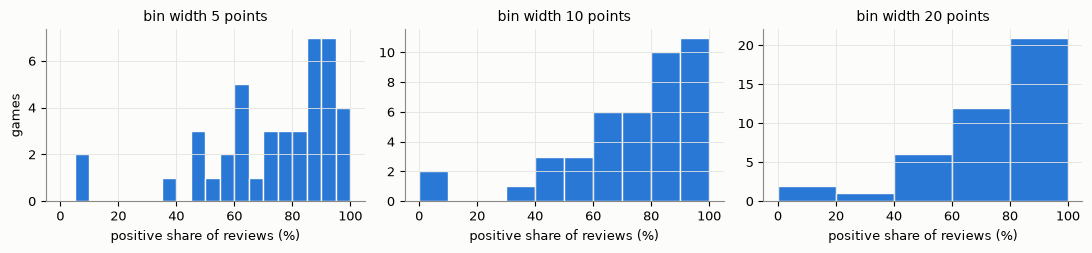

skewness: -1.32 | n = 42 | games below 50 %: 6 | at or above 80 %: 21


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 2.6), sharey=False)
for ax, w in zip(axes, BIN_WIDTHS_TRIED):
    ax.hist(g.share_pct, bins=np.arange(0, 100 + w, w), color="#2a78d6", edgecolor="#fcfcfb")
    ax.set_title(f"bin width {w} points"); ax.set_xlabel("positive share of reviews (%)")
axes[0].set_ylabel("games")
plt.tight_layout(); plt.show()
print("skewness:", round(g.share_pct.skew(), 2), "| n =", len(g),
      "| games below 50 %:", int((g.share_pct < 50).sum()), "| at or above 80 %:", int((g.share_pct >= 80).sum()))

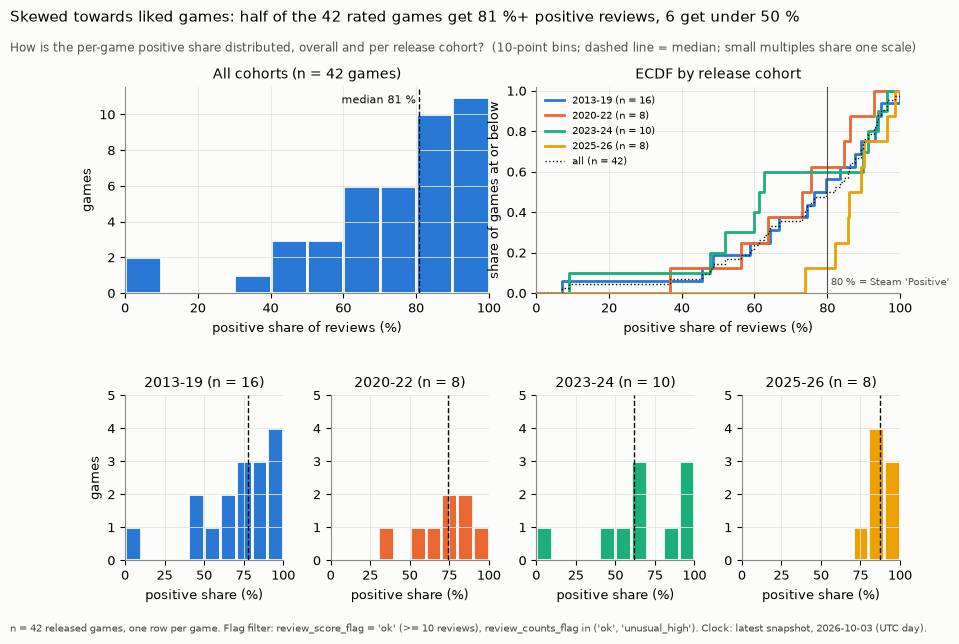

In [8]:
bins = np.arange(0, 100 + BIN_WIDTH, BIN_WIDTH)
fig = plt.figure(figsize=(10, 6.4))
gs = fig.add_gridspec(2, 4, height_ratios=[1.25, 1], hspace=0.55, wspace=0.3, top=0.86, bottom=0.12)
ax_h = fig.add_subplot(gs[0, :2]); ax_e = fig.add_subplot(gs[0, 2:])
ax_h.hist(g.share_pct, bins=bins, color="#2a78d6", edgecolor="#fcfcfb", linewidth=2)
ax_h.axvline(g.share_pct.median(), color=INK, lw=1, ls="--")
ax_h.text(g.share_pct.median() - 1, ax_h.get_ylim()[1] * 0.92, f"median {g.share_pct.median():.0f} %",
          ha="right", fontsize=8, color=INK)
ax_h.set(title=f"All cohorts (n = {len(g)} games)", xlabel="positive share of reviews (%)", ylabel="games", xlim=(0, 100))
for c in COHORTS:
    d = np.sort(g.loc[g.cohort == c, "share_pct"])
    ax_e.step(np.r_[0, d, 100], np.r_[0, np.arange(1, d.size + 1) / d.size, 1], where="post",
              color=COLORS[c], lw=2, label=f"{c} (n = {d.size})")
d = np.sort(g.share_pct)
ax_e.step(np.r_[0, d, 100], np.r_[0, np.arange(1, d.size + 1) / d.size, 1], where="post", color=INK, lw=1, ls=":",
          label=f"all (n = {d.size})")
ax_e.axvline(VERY_POSITIVE_PCT, color=MUTED, lw=0.8); ax_e.text(VERY_POSITIVE_PCT + 1, 0.04, "80 % = Steam 'Positive'",
                                                               ha="left", fontsize=7, color=MUTED)
ax_e.set(title="ECDF by release cohort", xlabel="positive share of reviews (%)",
         ylabel="share of games at or below", xlim=(0, 100), ylim=(0, 1.02))
ax_e.legend(fontsize=7, loc="upper left", frameon=False)
ymax = max(np.histogram(g.loc[g.cohort == c, "share_pct"], bins)[0].max() for c in COHORTS) + 1
for i, c in enumerate(COHORTS):
    ax = fig.add_subplot(gs[1, i]); d = g.loc[g.cohort == c, "share_pct"]
    ax.hist(d, bins=bins, color=COLORS[c], edgecolor="#fcfcfb", linewidth=2)
    ax.axvline(d.median(), color=INK, lw=1, ls="--")
    ax.set(title=f"{c} (n = {len(d)})", xlim=(0, 100), ylim=(0, ymax), xlabel="positive share (%)")
    if i == 0: ax.set_ylabel("games")
fig.suptitle(f"Skewed towards liked games: half of the {len(g)} rated games get {g.share_pct.median():.0f} %+ positive reviews, "
             f"{(g.share_pct < 50).sum()} get under 50 %",
             x=0.01, ha="left", fontsize=11)
fig.text(0.01, 0.915, "How is the per-game positive share distributed, overall and per release cohort?  "
         "(10-point bins; dashed line = median; small multiples share one scale)", fontsize=8.5, color=MUTED)
save(fig, "fig1_shape_positive_share",
     f"n = {len(g)} released games, one row per game. Flag filter: review_score_flag = 'ok' (>= 10 reviews), "
     "review_counts_flag in ('ok', 'unusual_high'). Clock: latest snapshot, 2026-10-03 (UTC day).")
plt.show()

## 2.4 Coverage, denominators and the flag filter

**Question:** for each release year, how many games could have a positive share, and how many have one we trust?
The denominator is the released sampled games; a game counts only with `review_score_flag = 'ok'`.

In [9]:
show_sql("06_coverage_by_year")
cov = query(con, "06_coverage_by_year")
cov["usable_pct_of_released"] = 100 * cov.usable_score / cov.released_games.replace(0, np.nan)
cov

-- =============================================================================
-- Question: For each release year, how many sampled games could have a positive
--           share, and how many actually have one we trust?
--
-- Result grain: one row per release year (release_year from the store text,
--               full or partial date) plus one row per game with no year (NULL).
-- Flag filter:  none - this table counts every flag value so the denominators
--               are visible: usable = review_score_flag 'ok' (>= 10 reviews).
-- Clock:        release_year is the store's calendar year; snapshot_date UTC.
-- =============================================================================

SELECT release_year,
       COUNT(*)                                                         AS sampled_games,
       SUM(coming_soon = 0)                                             AS released_games,
       SUM(coming_soon = 0 AND total_reviews > 0)                       AS with_any_review,
  

,release_year,sampled_games,released_games,with_any_review,usable_score,too_few_reviews,no_reviews,not_released,usable_pct_of_released
0,2013.0,1,1,1,1,0,0,0,100.00
1,2015.0,1,1,1,1,0,0,0,100.00
2,2016.0,3,3,3,3,0,0,0,100.00
3,2017.0,4,4,4,3,1,0,0,75.00
4,2018.0,7,7,7,6,1,0,0,85.71
5,2019.0,3,3,3,2,1,0,0,66.67
6,2020.0,5,5,5,3,2,0,0,60.00
7,2021.0,6,6,6,2,4,0,0,33.33
8,2022.0,9,9,8,3,5,1,0,33.33
9,2023.0,1,1,1,1,0,0,0,100.00


In [10]:
cov_c = g.groupby("cohort", observed=True).size().rename("usable").to_frame()
allg = games(ALL_SCORE_FLAGS, ALL_COUNT_FLAGS)
cov_c["released"] = allg.groupby("cohort", observed=True).size()
cov_c["usable_pct"] = 100 * cov_c.usable / cov_c.released
print("coverage per cohort (flag filter for 'usable': review_score_flag = 'ok'; denominator: all released games)")
cov_c

coverage per cohort (flag filter for 'usable': review_score_flag = 'ok'; denominator: all released games)


,usable,released,usable_pct
cohort,,,
2013-19,16,19,84.21
2020-22,8,20,40.00
2023-24,10,11,90.91
2025-26,8,20,40.00


**Coverage rules.** (1) A game's share needs at least `MIN_REVIEWS_PER_GAME` = 10 reviews: with 1-9 reviews the
share jumps in steps of 10-100 points (one review is 0 % or 100 %), and it is Steam's own threshold for showing a
score; enforced by `review_score_flag = 'ok'`. (2) A group median needs at least `MIN_GAMES_PER_GROUP` = 5 games:
below that the median is one or two games. Result **with and without rule (2)**, per single release year:

In [11]:
per_year = g.groupby("release_year").share_pct.agg(n_games="size", median_share="median")
per_year["median_with_rule"] = per_year.median_share.where(per_year.n_games >= MIN_GAMES_PER_GROUP)
print("flag filter:", SCORE_FLAGS, COUNT_FLAGS, "| rule: n_games >=", MIN_GAMES_PER_GROUP)
per_year

flag filter: ['ok'] ['ok', 'unusual_high'] | rule: n_games >= 5


,n_games,median_share,median_with_rule
release_year,,,
2013,1,83.59,NaN
2015,1,93.13,NaN
2016,3,76.34,NaN
2017,3,74.32,NaN
2018,6,77.08,77.08
2019,2,76.81,NaN
2020,3,56.25,NaN
2021,2,74.28,NaN
2022,3,84.62,NaN


**Flag filter varied.** The cohort medians under the reported filter and under the two alternatives:
with 1-9-review games admitted (`SCORE_FLAGS_ALT`), and without the three `unusual_high` games (`COUNT_FLAGS_ALT`).

In [12]:
filters = {
    "reported: score ok, counts ok+unusual_high": (SCORE_FLAGS, COUNT_FLAGS),
    "score ok, counts ok only (drop 3 popular)": (SCORE_FLAGS, COUNT_FLAGS_ALT),
    "score ok or 1-9 reviews, counts ok+unusual_high": (SCORE_FLAGS_ALT, COUNT_FLAGS),
}
flag_cmp = pd.concat({l: games(*f).groupby("cohort", observed=True).share_pct.agg(n="size", median="median")
                      for l, f in filters.items()}, axis=1)
flag_cmp

reported: score ok, counts ok+unusual_high        score ok, counts ok only (drop 3 popular)        score ok or 1-9 reviews, counts ok+unusual_high       
                                                 n median                                         n median                                               n median
cohort                                                                                                                                                           
2013-19                                         16  78.01                                        14  78.01                                              19  79.67
2020-22                                          8  74.28                                         8  74.28                                              19  66.67
2023-24                                         10  62.00                                        10  62.00                                              11  61.25
2025-26                                          8  87.60                                         7  86.00                                              16  87.60

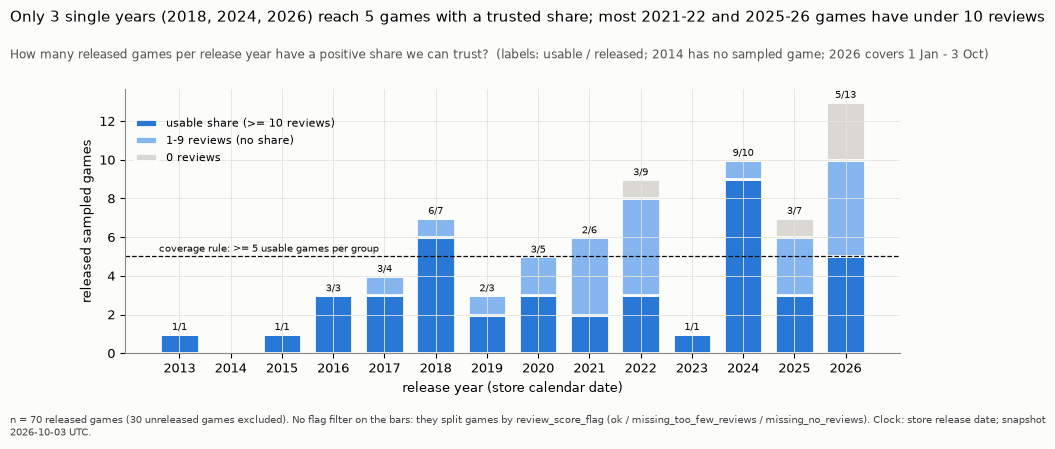

In [13]:
years = list(range(int(cov.release_year.min()), 2027))
c = cov.set_index("release_year").reindex(years).fillna(0)
fig, ax = plt.subplots(figsize=(10, 4.4))
fig.subplots_adjust(top=0.80, bottom=0.2)
parts = [("usable_score", "usable share (>= 10 reviews)", "#2a78d6", None),
         ("too_few_reviews", "1-9 reviews (no share)", "#86b6ef", None),
         ("no_reviews", "0 reviews", "#d9d8d3", None)]
bottom = np.zeros(len(years))
for col, label, color, hatch in parts:
    ax.bar(years, c[col], bottom=bottom, color=color, edgecolor="#fcfcfb", linewidth=2, label=label, width=0.75)
    bottom += c[col].to_numpy()
for x, u, r in zip(years, c.usable_score, c.released_games):
    if r: ax.text(x, r + 0.2, f"{int(u)}/{int(r)}", ha="center", fontsize=7.5, color=INK)
ax.axhline(MIN_GAMES_PER_GROUP, color=INK, lw=0.9, ls="--")
ax.text(years[0] - 0.4, MIN_GAMES_PER_GROUP + 0.25, f"coverage rule: >= {MIN_GAMES_PER_GROUP} usable games per group",
        fontsize=7.5, color=INK)
ax.set(xticks=years, ylabel="released sampled games", xlabel="release year (store calendar date)", ylim=(0, None))
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(0.0, 0.93))
ok_years = [int(y) for y, u in zip(years, c.usable_score) if u >= MIN_GAMES_PER_GROUP]
fig.suptitle(f"Only {len(ok_years)} single years ({', '.join(map(str, ok_years))}) reach {MIN_GAMES_PER_GROUP} games with a trusted share; "
             "most 2021-22 and 2025-26 games have under 10 reviews",
             x=0.01, ha="left", fontsize=11)
fig.text(0.01, 0.87, "How many released games per release year have a positive share we can trust?  "
         "(labels: usable / released; 2014 has no sampled game; 2026 covers 1 Jan - 3 Oct)", fontsize=8.5, color=MUTED)
save(fig, "fig2_coverage_by_year",
     f"n = {int(c.released_games.sum())} released games (30 unreleased games excluded). No flag filter on the bars: "
     "they split games by review_score_flag (ok / missing_too_few_reviews / missing_no_reviews). Clock: store release date; snapshot 2026-10-03 UTC.")
plt.show()

## 2.5 Time

**Clock.** `release_date` is the calendar date shown on the US English store page; it has no time of day and no
time zone, so there is nothing to `tz_convert` - grouping by year, month and weekday uses that date as given.
`snapshot_date` and `retrieved_at` are UTC. Game age at the snapshot = UTC snapshot day minus store date; the
possible one-day offset does not matter at the 90-day scale we use. There is **one snapshot** (2026-10-03), so the
only time dimension is release time, not change over time.

**Edges.** The first year (2013) has one game; 2014 has none. The last year (2026) is cut at the retrieval day:
1 January - 3 October, 276 of 365 days, and games released in the last weeks had no time to collect reviews.

In [14]:
rel = query(con, "07_releases_by_month")
rel["release_date"] = pd.to_datetime(rel.release_date)
print("first and last full release date (flag 'ok'):", rel.release_date.min().date(), "..", rel.release_date.max().date())
print("released games with a full date:", rel.games.sum())
allg["age_band"] = pd.cut(allg.age_days, AGE_BANDS_DAYS, right=False,
                          labels=["< 90 days", "90-364 days", "1-3 years", "> 3 years"])
age_cov = allg.groupby("age_band", observed=True).agg(released=("app_key", "size"),
                                                      usable=("review_score_flag", lambda s: (s == "ok").sum()))
age_cov["usable_pct"] = 100 * age_cov.usable / age_cov.released
print("flag filter for 'usable': review_score_flag = 'ok'; all released games, clock: age at the UTC snapshot day")
age_cov

first and last full release date (flag 'ok'): 2013-10-14 .. 2026-09-23
released games with a full date: 70
flag filter for 'usable': review_score_flag = 'ok'; all released games, clock: age at the UTC snapshot day


,released,usable,usable_pct
age_band,,,
< 90 days,6,2,33.33
90-364 days,10,3,30.00
1-3 years,14,12,85.71
> 3 years,40,25,62.50


In [15]:
complete = rel[rel.release_year <= 2025]          # whole calendar years only, so every month had the same chance
month = complete.groupby("release_month").games.sum().reindex(range(1, 13), fill_value=0)
month_all = rel.groupby("release_month").games.sum().reindex(range(1, 13), fill_value=0)
weekday = rel.groupby("weekday").games.sum().reindex(range(7), fill_value=0)
weekday.index = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
print("month of year, complete years 2013-2025 (n =", month.sum(), ") and with 2026 (n =", month_all.sum(), ")")
print(pd.DataFrame({"2013-2025": month, "incl. 2026": month_all}).T)
print("weekday (n =", weekday.sum(), ")"); print(weekday.to_frame().T)

month of year, complete years 2013-2025 (n = 57 ) and with 2026 (n = 70 )
release_month  1   2   3   4   5   6   7   8   9   10  11  12
2013-2025       1   4   4   5   2   3   3  10   4   9   6   6
incl. 2026      1   6   6   5   4   4   5  13   5   9   6   6
weekday (n = 70 )
       Sun  Mon  Tue  Wed  Thu  Fri  Sat
games    3   15    8   12   15   14    3


In [16]:
cal = rel[(rel.release_date.dt.strftime("%m-%d") >= "12-20") | (rel.release_date.dt.strftime("%m-%d") <= "01-02")]
print("releases between 20 Dec and 2 Jan (holidays, Steam Winter Sale window):")
print(cal[["release_date", "games"]].to_string(index=False))
print("31 December dates:", int((rel.release_date.dt.strftime("%m-%d") == "12-31").sum()))

releases between 20 Dec and 2 Jan (holidays, Steam Winter Sale window):
release_date  games
  2017-12-31      1
  2018-12-31      1
  2024-12-20      1
  2025-12-25      1
  2025-12-29      1
31 December dates: 2


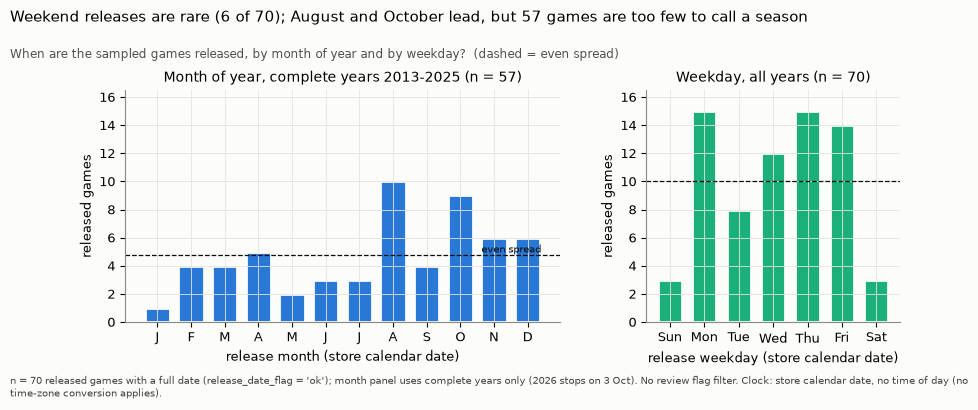

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [12, 7]})
fig.subplots_adjust(top=0.78, bottom=0.2, wspace=0.25)
ax1.bar(range(1, 13), month, color="#2a78d6", edgecolor="#fcfcfb", linewidth=2, width=0.75)
ax1.axhline(month.sum() / 12, color=INK, lw=0.9, ls="--")
ax1.text(12.4, month.sum() / 12 + 0.2, "even spread", ha="right", fontsize=7.5, color=INK)
ax1.set(xticks=range(1, 13), xticklabels=list("JFMAMJJASOND"), ylabel="released games",
        xlabel="release month (store calendar date)", title=f"Month of year, complete years 2013-2025 (n = {month.sum()})")
ax2.bar(weekday.index, weekday, color="#1baf7a", edgecolor="#fcfcfb", linewidth=2, width=0.7)
ax2.axhline(weekday.sum() / 7, color=INK, lw=0.9, ls="--")
ax2.set(ylabel="released games", xlabel="release weekday (store calendar date)",
        title=f"Weekday, all years (n = {weekday.sum()})")
top = max(month.max(), weekday.max()) + 1.5
ax1.set_ylim(0, top); ax2.set_ylim(0, top)        # same scale in both panels
fig.suptitle(f"Weekend releases are rare ({weekday[['Sat', 'Sun']].sum()} of {weekday.sum()}); August and October lead, "
             f"but {month.sum()} games are too few to call a season",
             x=0.01, ha="left", fontsize=11)
fig.text(0.01, 0.86, "When are the sampled games released, by month of year and by weekday?  (dashed = even spread)",
         fontsize=8.5, color=MUTED)
save(fig, "fig3_release_calendar",
     f"n = {weekday.sum()} released games with a full date (release_date_flag = 'ok'); month panel uses complete years only "
     "(2026 stops on 3 Oct). No review flag filter. Clock: store calendar date, no time of day (no time-zone conversion applies).")
plt.show()

## 2.6 Relationships

**Question:** do more popular games (more reviews) or more expensive games get a higher positive share?
Plotted first, then measured. Reviews are shown on a log scale (1.0-4.3 in log10, i.e. 10 to 19,627).

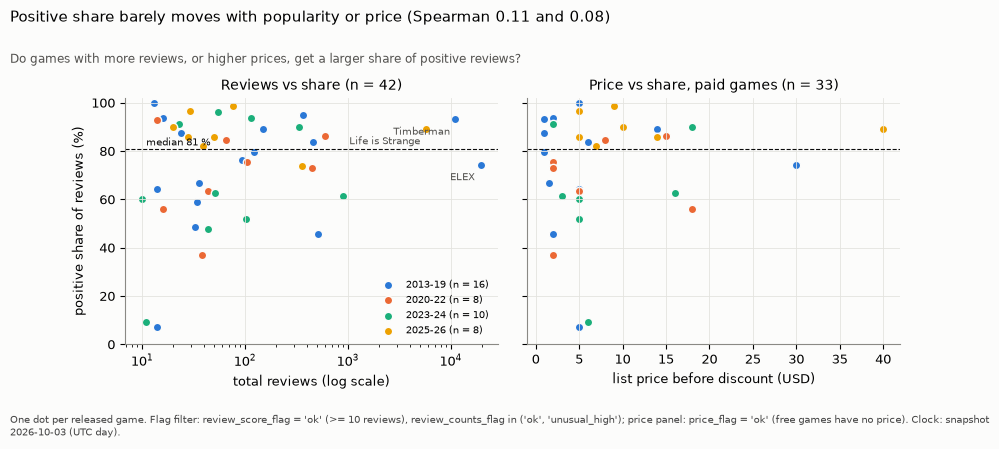

In [18]:
g["log10_reviews"] = np.log10(g.total_reviews)
paid = g[g.price_usd.notna()]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
fig.subplots_adjust(top=0.78, bottom=0.22, wspace=0.08)
for c in COHORTS:
    d = g[g.cohort == c]; p = paid[paid.cohort == c]
    ax1.scatter(d.total_reviews, d.share_pct, s=36, color=COLORS[c], edgecolor="#fcfcfb", linewidth=1, label=f"{c} (n = {len(d)})")
    ax2.scatter(p.price_usd, p.share_pct, s=36, color=COLORS[c], edgecolor="#fcfcfb", linewidth=1)
for _, r in g[g.review_counts_flag == "unusual_high"].iterrows():
    ax1.annotate(r.store_name.split(":")[0], (r.total_reviews, r.share_pct), xytext=(-4, -11), textcoords="offset points",
                 fontsize=7, ha="right", color=MUTED)
for ax in (ax1, ax2):
    ax.axhline(g.share_pct.median(), color=INK, lw=0.8, ls="--")
ax1.text(11, g.share_pct.median() + 1.5, f"median {g.share_pct.median():.0f} %", fontsize=7.5, color=INK)
ax1.set(xscale="log", xlabel="total reviews (log scale)", ylabel="positive share of reviews (%)", ylim=(0, 102),
        title=f"Reviews vs share (n = {len(g)})")
ax2.set(xlabel="list price before discount (USD)", title=f"Price vs share, paid games (n = {len(paid)})")
ax1.legend(frameon=False, fontsize=7, loc="lower right")
sp_r = g.log10_reviews.rank().corr(g.share_pct.rank()); sp_p = paid.price_usd.rank().corr(paid.share_pct.rank())
fig.suptitle(f"Positive share barely moves with popularity or price (Spearman {sp_r:.2f} and {sp_p:.2f})",
             x=0.01, ha="left", fontsize=11)
fig.text(0.01, 0.86, "Do games with more reviews, or higher prices, get a larger share of positive reviews?",
         fontsize=8.5, color=MUTED)
save(fig, "fig4_relationship_reviews_price",
     "One dot per released game. Flag filter: review_score_flag = 'ok' (>= 10 reviews), review_counts_flag in ('ok', 'unusual_high'); "
     "price panel: price_flag = 'ok' (free games have no price). Clock: snapshot 2026-10-03 (UTC day).")
plt.show()

In [19]:
def corr_row(d, x, label):
    return pd.Series({"n": len(d), "pearson": d[x].corr(d.share_pct), "spearman": d[x].rank().corr(d.share_pct.rank())},
                     name=label)
rows = [corr_row(g, "log10_reviews", "log10 reviews: all"),
        corr_row(g[g.review_counts_flag == "ok"], "log10_reviews", "log10 reviews: without 3 unusual_high"),
        corr_row(g[g.share_pct >= 20], "log10_reviews", "log10 reviews: without 2 games below 20 %"),
        corr_row(paid, "price_usd", "price: all paid"),
        corr_row(paid[paid.review_counts_flag == "ok"], "price_usd", "price: without unusual_high"),
        corr_row(paid[paid.price_usd < 20], "price_usd", "price: under 20 USD")]
for c in COHORTS:
    rows.append(corr_row(g[g.cohort == c], "log10_reviews", f"log10 reviews within {c}"))
print("flag filter:", SCORE_FLAGS, COUNT_FLAGS, "(rows state further removals)")
pd.DataFrame(rows).round(2)

flag filter: ['ok'] ['ok', 'unusual_high'] (rows state further removals)


,n,pearson,spearman
log10 reviews: all,42.0,0.22,0.11
log10 reviews: without 3 unusual_high,39.0,0.18,0.06
log10 reviews: without 2 games below 20 %,40.0,0.09,-0.02
price: all paid,33.0,0.15,0.08
price: without unusual_high,30.0,0.15,0.13
price: under 20 USD,31.0,0.12,0.05
log10 reviews within 2013-19,16.0,0.23,0.06
log10 reviews within 2020-22,8.0,0.27,0.21
log10 reviews within 2023-24,10.0,0.36,0.38
log10 reviews within 2025-26,8.0,-0.19,-0.14


## 2.7 One comparison, with an interval - and a count of our looks

**Comparison:** median positive share of the newest cohort (released 2025-2026) against all older games
(2013-2024). Unit: the **game** - one row per game is already the independent unit (there is one snapshot, so no
repeated measures to aggregate). Interval: percentile bootstrap of the difference in medians, resampling games
within each group, `N_BOOT` = 10,000, seed `SEED`.

In [20]:
new = g[g.cohort.isin(COMPARE_NEW)]; old = g[g.cohort.isin(COMPARE_OLD)]
diff, lo, hi = median_diff_ci(new.share_pct, old.share_pct, N_BOOT, SEED)
print(f"new (2025-26) n = {len(new)}, median {new.share_pct.median():.1f} %")
print(f"old (2013-24) n = {len(old)}, median {old.share_pct.median():.1f} %")
print(f"difference {diff:+.1f} points, 95 % bootstrap interval [{lo:+.1f}, {hi:+.1f}]  (flag filter: {SCORE_FLAGS}, {COUNT_FLAGS})")

new (2025-26) n = 8, median 87.6 %
old (2013-24) n = 34, median 74.9 %
difference +12.7 points, 95 % bootstrap interval [+0.4, +27.4]  (flag filter: ['ok'], ['ok', 'unusual_high'])


**Composition check.** Are the two groups made of the same mixture? A game released in 2025-26 only reaches the
rated group if it collected 10 reviews quickly, so the new group may be a more selected mixture.

In [21]:
def mix(d, released):
    return pd.Series({"games": len(d), "pct_of_released_rated": 100 * len(d) / len(released),
                      "median_reviews": d.total_reviews.median(), "pct_50plus_reviews": 100 * (d.total_reviews >= 50).mean(),
                      "pct_indie": 100 * d.is_indie.mean(), "pct_free": 100 * d.is_free.mean(),
                      "median_price_usd": d.price_usd.median(), "median_age_days": d.age_days.median()})
mixture = pd.DataFrame({"2025-26": mix(new, allg[allg.cohort.isin(COMPARE_NEW)]),
                        "2013-24": mix(old, allg[allg.cohort.isin(COMPARE_OLD)])})
mixture.round(1)

,2025-26,2013-24
games,8.0,34.0
pct_of_released_rated,40.0,68.0
median_reviews,44.5,53.0
pct_50plus_reviews,50.0,52.9
pct_indie,62.5,79.4
pct_free,12.5,23.5
median_price_usd,9.0,5.0
median_age_days,225.0,2240.0


In [22]:
strata = []
for label, (lo_r, hi_r) in REVIEW_STRATA.items():
    a = new[new.total_reviews.between(lo_r, hi_r)].share_pct; b = old[old.total_reviews.between(lo_r, hi_r)].share_pct
    d, l, h = median_diff_ci(a, b, N_BOOT, SEED)
    strata.append({"stratum": label, "n_new": len(a), "n_old": len(b), "median_new": a.median(), "median_old": b.median(),
                   "diff": d, "ci_low": l, "ci_high": h})
for label, flag in [("Indie", 1), ("not Indie", 0)]:
    a = new[new.is_indie == flag].share_pct; b = old[old.is_indie == flag].share_pct
    if len(a) and len(b):
        d, l, h = median_diff_ci(a, b, N_BOOT, SEED)
        strata.append({"stratum": label, "n_new": len(a), "n_old": len(b), "median_new": a.median(), "median_old": b.median(),
                       "diff": d, "ci_low": l, "ci_high": h})
strata.insert(0, {"stratum": "all", "n_new": len(new), "n_old": len(old), "median_new": new.share_pct.median(),
                  "median_old": old.share_pct.median(), "diff": diff, "ci_low": lo, "ci_high": hi})
strata = pd.DataFrame(strata).set_index("stratum")
strata.round(1)

,n_new,n_old,median_new,median_old,diff,ci_low,ci_high
stratum,,,,,,,
all,8,34,87.6,74.9,12.7,0.4,27.4
10-49 reviews,4,16,87.9,61.8,26.0,1.7,40.8
50+ reviews,4,18,87.6,81.6,6.0,-9.3,20.2
Indie,5,27,86.0,83.6,2.4,-10.7,23.3
not Indie,3,7,89.2,60.0,29.2,12.6,48.1


**Looks.** Every group comparison of positive share computed while exploring, in this notebook or in scratch work
before it, is listed here. The 2.7 comparison was chosen because it is the M0 question (change by release year),
not because it was the largest difference - but it *is* also the largest of the cohort contrasts.

In [23]:
LOOKS = [f"cohort {a} vs {b}" for i, a in enumerate(COHORTS) for b in list(COHORTS)[i + 1:]]   # 6 pairs
LOOKS += ["2025-26 vs 2013-24 (the reported one)", "Indie vs not Indie", "free vs paid",
          "single years 2018 vs 2024 vs 2026 (rule-passing years)",
          "reviews vs share (Pearson, Spearman)", "price vs share (Pearson, Spearman)",
          "cohort medians under 3 flag filters", "2025-26 vs 2013-24 within 2 review strata and 2 Indie strata"]
other = {"Indie vs not Indie": median_diff_ci(g[g.is_indie == 1].share_pct, g[g.is_indie == 0].share_pct, N_BOOT, SEED),
         "free vs paid": median_diff_ci(g[g.is_free == 1].share_pct, g[g.is_free == 0].share_pct, N_BOOT, SEED)}
print("looks:", len(LOOKS), "items, about", 6 + 1 + 2 + 3 + 2 * 2 + 3 * 4 + 4, "individual numbers compared")
for k, (d, l, h) in other.items():
    print(f"  {k}: {d:+.1f} points [{l:+.1f}, {h:+.1f}]")

looks: 14 items, about 32 individual numbers compared
  Indie vs not Indie: +16.9 points [-4.6, +30.5]
  free vs paid: -5.7 points [-30.4, +20.8]


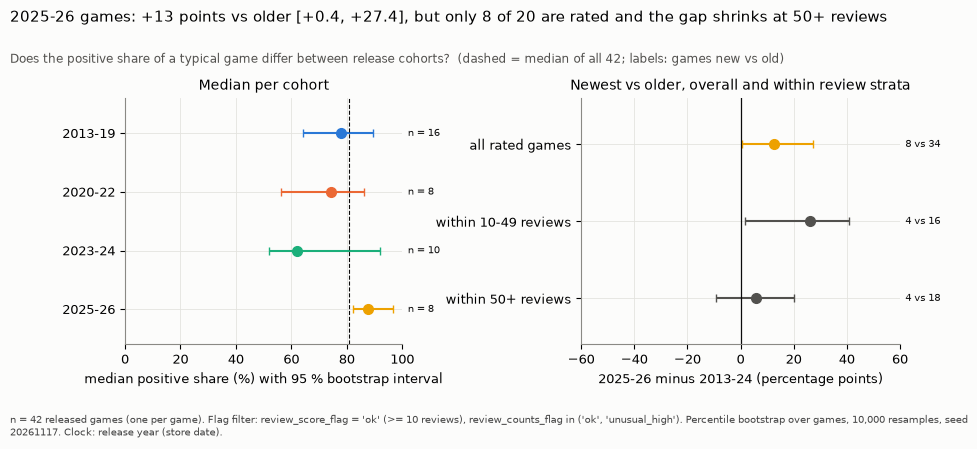

In [24]:
rng = np.random.default_rng(SEED)
def median_ci(x):
    x = np.asarray(x, float); m = np.median(rng.choice(x, (N_BOOT, x.size)), axis=1)
    return np.median(x), *np.quantile(m, [0.025, 0.975])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.4), gridspec_kw={"width_ratios": [1, 1.15]})
fig.subplots_adjust(top=0.78, bottom=0.22, wspace=0.6)
for i, c in enumerate(COHORTS):
    d = g[g.cohort == c].share_pct; m, l, h = median_ci(d)
    ax1.errorbar(m, i, xerr=[[m - l], [h - m]], fmt="o", ms=7, color=COLORS[c], capsize=3, lw=1.5)
    ax1.text(102, i, f"n = {len(d)}", va="center", fontsize=7.5, color=INK)
ax1.axvline(g.share_pct.median(), color=INK, lw=0.8, ls="--")
ax1.set(yticks=range(len(COHORTS)), yticklabels=list(COHORTS), xlim=(0, 100), ylim=(-0.6, len(COHORTS) - 0.4),
        xlabel="median positive share (%) with 95 % bootstrap interval", title="Median per cohort")
ax1.invert_yaxis()
show = strata.loc[["all", "10-49 reviews", "50+ reviews"]]
for i, (label, r) in enumerate(show.iterrows()):
    ax2.errorbar(r["diff"], i, xerr=[[r["diff"] - r.ci_low], [r.ci_high - r["diff"]]], fmt="o", ms=7,
                 color="#eda100" if i == 0 else MUTED, capsize=3, lw=1.5)
    ax2.text(62, i, f"{int(r.n_new)} vs {int(r.n_old)}", va="center", fontsize=7.5, color=INK)
ax2.axvline(0, color=INK, lw=0.9)
ax2.set(yticks=range(len(show)), yticklabels=["all rated games", "within 10-49 reviews", "within 50+ reviews"],
        xlim=(-60, 60), ylim=(-0.6, len(show) - 0.4),
        xlabel="2025-26 minus 2013-24 (percentage points)", title="Newest vs older, overall and within review strata")
ax2.invert_yaxis()
fig.suptitle(f"2025-26 games: {diff:+.0f} points vs older [{lo:+.1f}, {hi:+.1f}], but only {len(new)} of "
             f"{(allg.cohort.isin(COMPARE_NEW)).sum()} are rated and the gap shrinks at 50+ reviews",
             x=0.01, ha="left", fontsize=11)
fig.text(0.01, 0.86, "Does the positive share of a typical game differ between release cohorts?  "
         "(dashed = median of all 42; labels: games new vs old)", fontsize=8.5, color=MUTED)
save(fig, "fig5_cohort_comparison",
     f"n = {len(g)} released games (one per game). Flag filter: review_score_flag = 'ok' (>= 10 reviews), review_counts_flag in "
     f"('ok', 'unusual_high'). Percentile bootstrap over games, {N_BOOT:,} resamples, seed {SEED}. Clock: release year (store date).")
plt.show()

## Decisions used, and proof the database is unchanged

In [25]:
for k in ["SCORE_FLAGS", "SCORE_FLAGS_ALT", "COUNT_FLAGS", "COUNT_FLAGS_ALT", "COHORTS", "COMPARE_NEW", "COMPARE_OLD",
          "REVIEW_STRATA", "MIN_REVIEWS_PER_GAME", "MIN_GAMES_PER_GROUP", "BIN_WIDTHS_TRIED", "BIN_WIDTH",
          "VERY_POSITIVE_PCT", "AGE_BANDS_DAYS", "SNAPSHOT_CLOCK", "N_BOOT", "SEED"]:
    print(f"{k:22} {globals()[k]}")
AFTER = table_fingerprints(con)
assert AFTER == BEFORE, "the notebook changed the database"
print("\ndatabase unchanged:", len(AFTER), "tables, sha256 before = after")
print("figures written:", sorted(p.name for p in (ROOT / "figures").glob("*.png")))
con.close()

SCORE_FLAGS            ['ok']
SCORE_FLAGS_ALT        ['ok', 'missing_too_few_reviews']
COUNT_FLAGS            ['ok', 'unusual_high']
COUNT_FLAGS_ALT        ['ok']
COHORTS                {'2013-19': (2013, 2019), '2020-22': (2020, 2022), '2023-24': (2023, 2024), '2025-26': (2025, 2026)}
COMPARE_NEW            ['2025-26']
COMPARE_OLD            ['2013-19', '2020-22', '2023-24']
REVIEW_STRATA          {'10-49 reviews': (10, 49), '50+ reviews': (50, 1000000000)}
MIN_REVIEWS_PER_GAME   10
MIN_GAMES_PER_GROUP    5
BIN_WIDTHS_TRIED       [5, 10, 20]
BIN_WIDTH              10
VERY_POSITIVE_PCT      80
AGE_BANDS_DAYS         [0, 90, 365, 1095, 1000000]
SNAPSHOT_CLOCK         UTC
N_BOOT                 10000
SEED                   20261117



database unchanged: 23 tables, sha256 before = after
figures written: ['fig1_shape_positive_share.png', 'fig2_coverage_by_year.png', 'fig3_release_calendar.png', 'fig4_relationship_reviews_price.png', 'fig5_cohort_comparison.png']
